# 多元线性回归（Python 3.11）

多元线性回归用多个自变量共同解释一个连续型因变量，模型形式为：

$$y_i=\beta_0+\beta_1x_{i1}+\beta_2x_{i2}+\cdots+\beta_kx_{ik}+\varepsilon_i$$

其中 $\beta_0$ 是截距，$\beta_j$ 表示在其他变量保持不变时，$x_j$ 每增加 1 个单位，$y$ 的平均变化量。

本 Notebook 使用 NumPy 的普通最小二乘法（OLS）和 SciPy 的统计分布实现，不需要安装 `scikit-learn` 或 `statsmodels`。内容包括：

1. 数据准备和模型拟合；
2. 回归系数、标准误、t 检验、p 值和置信区间；
3. $R^2$、调整 $R^2$、F 检验、RMSE、MAE；
4. VIF 多重共线性检查和残差诊断；
5. 使用拟合好的模型对新样本进行预测。

## 0. 应用场景与适用条件

### 什么时候用它

多元线性回归回答两个问题：**在其他变量保持不变时，某个因素对结果的平均影响有多大**；以及**用这组因素能多大程度预测结果**。

| 场景 | 关心的问题 | 本 Notebook 中的例子 |
| --- | --- | --- |
| 影响因素分析 | 哪个因素影响最大、每增加 1 单位带来多少变化 | 广告投入、门店面积、员工人数对销售额的影响 |
| 预测与估算 | 给定一组自变量，预测连续型结果 | 新门店开业前估算销售额 |
| 控制与调优 | 在预算/资源约束下，调整哪些变量最划算 | 有限广告预算如何分配 |
| 基线模型 | 作为简单可解释的对照，再与机器学习模型比较 | 与随机森林回归的结果对比 |

### 适用条件（经典假设）

1. **线性**：$y$ 与每个 $x_j$ 的关系大致线性。若呈曲线关系，可先做变换（取对数、平方根），或加入多项式项与交互项。
2. **误差独立**：样本之间互不影响。时间序列、空间数据常违反这一条，会低估标准误。
3. **同方差**：残差的波动幅度不随预测值明显变化。若残差图呈喇叭形（异方差），应改用加权最小二乘或稳健标准误。
4. **误差近似正态**：小样本时 t 检验、F 检验、置信区间都依赖它；大样本可依赖中心极限定理。
5. **无完全共线性**：解释变量之间不能互相线性表出。用 VIF 检查，VIF > 10 通常需要删变量或合并变量。
6. **无强影响点**：个别异常值或高杠杆点可能显著改变系数，需结合业务判断是否剔除。
7. **样本量足够**：至少要满足 $n > k+1$（$k$ 为特征个数）；经验上希望 $n \ge 10\sim20$ 倍参数个数，否则系数不稳、$R^2$ 容易虚高。
8. **变量已数值化**：因变量必须是连续数值；类别变量（地区、行业等）要做哑变量（独热）编码，不能直接代入。
9. **预测不外推**：新样本的取值应落在训练数据覆盖的范围内，远距离外推不可靠。

### 什么情况下应换别的方法

| 数据特点 | 更适合的模型 |
| --- | --- |
| 因变量是 0/1（是否购买、是否违约） | 逻辑回归 |
| 因变量是计数（次数、人数） | 泊松回归 / 负二项回归 |
| 明显非线性、交互关系复杂 | 多项式回归、随机森林、梯度提升树 |
| 有趋势与季节性的时间序列 | ARIMA 等时间序列模型 |
| 存在自相关或异方差 | 稳健标准误 / 广义最小二乘 |
| 变量互为因果、遗漏关键变量 | 先解决内生性（工具变量、面板固定效应），否则系数不能当作因果解释 |

> 显著性不等于因果：$\beta_j$ 的可靠解释是「在指定模型和假设下，$x_j$ 与 $y$ 的偏相关强度」，而不是「改变 $x_j$ 一定会改变 $y$」。

### 复用方式（配套建模工具.py）

本 Notebook 讲原理用的函数已经同步抽取到同目录的 **`建模工具.py`**，新题目直接导入即可，不必再复制粘贴：

```python
import 建模工具
model = 建模工具.fit_multiple_linear_regression(X, y, feature_names=feature_names, confidence=0.95)
print(model['coefficient_table'])            # 系数、标准误、t 值、p 值、置信区间
print(model['vif_table'])                    # 多重共线性检查
pred = 建模工具.predict_multiple_linear_regression(model, new_samples)
```

下面的讲解和示例代码全部保留原样，只在开头多一次导入、末尾多一次“模块版结果是否与 Notebook 版一致”的校验。

In [ ]:
# ============================================================
# 复用入口：本 Notebook 的函数已抽成同目录的 建模工具.py
# 统一用 建模工具.xxx 的形式调用，不会覆盖本 Notebook 后面自己定义的同名函数
# ============================================================
import sys
from pathlib import Path

# 内核工作目录可能是本 Notebook 所在目录，也可能是仓库根目录，两种都兼容
for _p in (Path.cwd(), Path.cwd() / "模型"):
    if _p.is_dir() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import 建模工具

print("建模工具 版本：", 建模工具.__version__)
print("可复用对象：", "、".join(建模工具.__all__))

之后深入方向可以是看应用场景，什么条件下应用这个

In [7]:
# ============================================================
# 1. 导入依赖并设置绘图环境
# ============================================================
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

# 尽量使用系统中文字体，避免图表中的中文显示为方框。
# 如果本机没有 SimHei，Matplotlib 会继续尝试后面的字体。
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print(f'Python 版本：{sys.version.split()[0]}')
print(f'NumPy 版本：{np.__version__}')
print(f'Pandas 版本：{pd.__version__}')

Python 版本：3.11.9
NumPy 版本：2.4.6
Pandas 版本：3.1.0


## 1. 准备数据

下面用可重复生成的模拟数据演示完整流程，三个特征分别表示广告投入、门店面积和员工人数。实际使用时，把数据换成本地的 CSV/Excel 数据即可。

因变量应当是连续数值；分类变量不能直接代入，需要先做独热编码或其他数值化处理。

In [2]:
# ============================================================
# 2. 生成示例数据
# random seed 固定后，每次运行都会得到同一批样本，便于复现结果。
# ============================================================
rng = np.random.default_rng(42)
sample_count = 120

# 三个自变量的取值范围尽量符合现实业务含义。
advertising = rng.normal(loc=30, scale=8, size=sample_count)
store_area = rng.normal(loc=100, scale=20, size=sample_count)
employees = rng.integers(low=3, high=16, size=sample_count).astype(float)

# 人为设置真实系数，再加入随机噪声，模拟观测误差和未纳入模型的因素。
noise = rng.normal(loc=0, scale=4.5, size=sample_count)
sales = (
    10.0
    + 1.8 * advertising
    + 0.65 * store_area
    + 2.2 * employees
    + noise
)

data = pd.DataFrame({
    '广告投入': advertising,
    '门店面积': store_area,
    '员工人数': employees,
    '销售额': sales,
})

feature_names = ['广告投入', '门店面积', '员工人数']
target_name = '销售额'

display(data.head())
print(f'样本数：{len(data)}，特征数：{len(feature_names)}')

,广告投入,门店面积,员工人数,销售额
0,32.437737,79.530050,4.0,130.214431
1,21.680127,103.585513,7.0,130.081197
2,36.003610,104.399934,15.0,167.761206
3,37.524518,127.183752,8.0,179.289550
4,14.391718,116.702225,4.0,128.334615


样本数：120，特征数：3


### 使用自己的数据

把下面的代码改成自己的文件路径和列名。缺失值应当根据业务含义删除或填补，不能直接让 `NaN` 参与矩阵运算。

```python
# data = pd.read_csv('your_data.csv')          # 也可以使用 read_excel
# feature_names = ['特征1', '特征2', '特征3']
# target_name = '目标变量'
# data = data.dropna(subset=feature_names + [target_name]).copy()
```

## 2. 普通最小二乘估计

把截距看作一个恒等于 1 的自变量，则设计矩阵为 $X=[\mathbf{1},X_1,\ldots,X_k]$。OLS 通过最小化残差平方和

$$\mathrm{SSE}=\sum_{i=1}^{n}(y_i-\hat y_i)^2$$

求系数。矩阵形式的最优解满足正规方程 $X^TX\hat\beta=X^Ty$。代码使用 `numpy.linalg.lstsq`，它比手工求逆更稳定。

标准误、t 检验和置信区间依赖经典线性回归假设：线性关系、误差独立、同方差、误差近似正态，以及解释变量之间不存在完全共线性。

In [3]:
# ============================================================
# 3. 多元线性回归核心函数
# ============================================================
def add_intercept(features):
    """在特征矩阵最左侧添加一列 1，用于估计截距项。

    参数
    ----
    features : 二维数组或 DataFrame，形状为 (n_samples, n_features)

    返回
    ----
    design_matrix : 形状为 (n_samples, n_features + 1) 的二维数组
    """
    feature_matrix = np.asarray(features, dtype=float)

    # 一维输入按“一个特征”处理；实际回归通常应传入二维矩阵。
    if feature_matrix.ndim == 1:
        feature_matrix = feature_matrix.reshape(-1, 1)
    if feature_matrix.ndim != 2:
        raise ValueError('features 必须是二维矩阵')

    # column_stack 会把全 1 列和原始特征按列拼接。
    ones = np.ones((feature_matrix.shape[0], 1), dtype=float)
    return np.column_stack((ones, feature_matrix))


def calculate_vif(features, feature_names):
    """计算每个特征的方差膨胀因子 VIF。

    VIF_j 等于把第 j 个特征作为因变量、其余特征作为自变量做回归后得到的
    1 / (1 - R_j^2)。VIF 越大，说明该特征越容易被其他特征线性解释。
    经验判断：VIF > 5 需关注，VIF > 10 通常认为共线性较严重。
    """
    feature_matrix = np.asarray(features, dtype=float)
    sample_count, feature_count = feature_matrix.shape
    vif_values = np.ones(feature_count, dtype=float)

    # 只有一个特征时不存在“由其他特征解释”的问题，VIF 记为 1。
    if feature_count == 1:
        return pd.DataFrame({'特征': feature_names, 'VIF': vif_values})

    for j in range(feature_count):
        target_j = feature_matrix[:, j]
        other_columns = np.delete(feature_matrix, j, axis=1)
        auxiliary_design = add_intercept(other_columns)

        # 辅助回归：用其他特征尽量解释当前特征。
        auxiliary_coefficients, *_ = np.linalg.lstsq(
            auxiliary_design, target_j, rcond=None
        )
        auxiliary_prediction = auxiliary_design @ auxiliary_coefficients
        auxiliary_residuals = target_j - auxiliary_prediction

        total_sum_squares = np.sum((target_j - target_j.mean()) ** 2)
        residual_sum_squares = np.sum(auxiliary_residuals ** 2)

        if total_sum_squares <= np.finfo(float).eps:
            # 特征本身是常数，无法进行有意义的共线性分析。
            vif_values[j] = np.inf
            continue

        auxiliary_r_squared = 1.0 - residual_sum_squares / total_sum_squares
        # 数值误差可能使 R² 略大于 1，先裁剪到合理区间。
        auxiliary_r_squared = np.clip(auxiliary_r_squared, 0.0, 1.0 - 1e-12)
        vif_values[j] = 1.0 / (1.0 - auxiliary_r_squared)

    return pd.DataFrame({'特征': feature_names, 'VIF': vif_values})


def fit_multiple_linear_regression(features, target, feature_names=None,
                                   confidence=0.95):
    """拟合多元线性回归，并返回系数、显著性检验和拟合优度。

    参数
    ----
    features : 二维数组或 DataFrame，形状为 (n_samples, n_features)
    target : 一维数组或 Series，形状为 (n_samples,)
    feature_names : 特征名称列表，默认自动命名为 x1、x2……
    confidence : 回归系数置信区间的置信水平

    返回
    ----
    字典，包含系数表、拟合值、残差、模型指标和置信水平。
    """
    feature_matrix = np.asarray(features, dtype=float)
    target_vector = np.asarray(target, dtype=float).reshape(-1)

    # 输入检查能在数据错误时给出明确提示，避免矩阵运算抛出难懂的错误。
    if feature_matrix.ndim != 2:
        raise ValueError('features 必须是二维矩阵')
    sample_count, feature_count = feature_matrix.shape
    if sample_count != target_vector.size:
        raise ValueError('特征行数与目标变量长度不一致')
    if sample_count <= feature_count + 1:
        raise ValueError('样本数不足：至少应大于特征数加 1')
    if not np.isfinite(feature_matrix).all():
        raise ValueError('特征中包含 NaN 或无穷大，请先清洗数据')
    if not np.isfinite(target_vector).all():
        raise ValueError('目标变量中包含 NaN 或无穷大，请先清洗数据')
    if not 0.0 < confidence < 1.0:
        raise ValueError('confidence 必须位于 0 和 1 之间')

    if feature_names is None:
        feature_names = [f'x{j + 1}' for j in range(feature_count)]
    if len(feature_names) != feature_count:
        raise ValueError('feature_names 的数量必须与特征列数一致')

    design_matrix = add_intercept(feature_matrix)
    parameter_count = design_matrix.shape[1]

    # 设计矩阵必须满列秩。若不满秩，说明存在完全共线性或重复变量。
    design_rank = np.linalg.matrix_rank(design_matrix)
    if design_rank < parameter_count:
        raise ValueError(
            '设计矩阵不满秩，可能存在完全共线性的变量，请删除或合并相关特征'
        )

    # OLS 系数：beta = argmin ||X beta - y||²。
    coefficients, *_ = np.linalg.lstsq(design_matrix, target_vector, rcond=None)
    fitted_values = design_matrix @ coefficients
    residuals = target_vector - fitted_values

    # 平方和分解：SST = SSR + SSE。
    residual_sum_squares = np.sum(residuals ** 2)
    total_sum_squares = np.sum((target_vector - target_vector.mean()) ** 2)
    regression_sum_squares = total_sum_squares - residual_sum_squares

    degrees_of_freedom_model = parameter_count - 1
    degrees_of_freedom_residual = sample_count - parameter_count

    # R² 表示已解释的变异比例；调整 R² 会惩罚无用的解释变量。
    r_squared = 1.0 - residual_sum_squares / total_sum_squares
    adjusted_r_squared = 1.0 - (
        (1.0 - r_squared) * (sample_count - 1) / degrees_of_freedom_residual
    )

    mean_squared_error = residual_sum_squares / degrees_of_freedom_residual
    root_mean_squared_error = np.sqrt(mean_squared_error)
    mean_absolute_error = np.mean(np.abs(residuals))

    # 回归均方除以残差均方，构造整体显著性 F 检验。
    f_statistic = (
        regression_sum_squares / degrees_of_freedom_model
    ) / mean_squared_error
    f_p_value = stats.f.sf(
        f_statistic, degrees_of_freedom_model, degrees_of_freedom_residual
    )

    # 系数协方差矩阵为 sigma² * (X'X)^(-1)。
    covariance_matrix = mean_squared_error * np.linalg.inv(
        design_matrix.T @ design_matrix
    )
    standard_errors = np.sqrt(np.diag(covariance_matrix))
    t_statistics = coefficients / standard_errors
    p_values = 2.0 * stats.t.sf(
        np.abs(t_statistics), degrees_of_freedom_residual
    )

    # 置信区间使用残差自由度对应的 t 分位数，而不是标准正态分位数。
    alpha = 1.0 - confidence
    t_critical = stats.t.ppf(
        1.0 - alpha / 2.0, degrees_of_freedom_residual
    )
    interval_margin = t_critical * standard_errors

    parameter_names = ['截距'] + list(feature_names)
    coefficient_table = pd.DataFrame({
        '变量': parameter_names,
        '系数': coefficients,
        '标准误': standard_errors,
        't值': t_statistics,
        'p值': p_values,
        f'{confidence:.0%}置信区间下限': coefficients - interval_margin,
        f'{confidence:.0%}置信区间上限': coefficients + interval_margin,
    })

    # Durbin-Watson 约为 2 时，残差序列没有明显的一阶自相关。
    durbin_watson = np.sum(np.diff(residuals) ** 2) / residual_sum_squares

    return {
        'coefficients': coefficients,
        'coefficient_table': coefficient_table,
        'feature_names': list(feature_names),
        'fitted_values': fitted_values,
        'residuals': residuals,
        'r_squared': r_squared,
        'adjusted_r_squared': adjusted_r_squared,
        'rmse': root_mean_squared_error,
        'mae': mean_absolute_error,
        'f_statistic': f_statistic,
        'f_p_value': f_p_value,
        'durbin_watson': durbin_watson,
        'condition_number': np.linalg.cond(design_matrix),
        'vif_table': calculate_vif(feature_matrix, feature_names),
        'confidence': confidence,
        'degrees_of_freedom_residual': degrees_of_freedom_residual,
    }


def predict_multiple_linear_regression(model, new_features):
    """使用已经拟合的模型预测新样本。"""
    new_matrix = np.asarray(new_features, dtype=float)
    if new_matrix.ndim == 1:
        new_matrix = new_matrix.reshape(1, -1)
    if new_matrix.ndim != 2:
        raise ValueError('new_features 必须是二维矩阵')
    if new_matrix.shape[1] != len(model['feature_names']):
        raise ValueError('新样本的特征数量必须与训练时一致')
    if not np.isfinite(new_matrix).all():
        raise ValueError('新样本中包含 NaN 或无穷大')

    return add_intercept(new_matrix) @ model['coefficients']

## 3. 拟合模型并解释结果

- **系数**：在其他特征固定不变时，该特征增加 1 个单位对目标变量的平均影响。
- **p 值**：通常以 0.05 为阈值。p 值较小说明“在控制其他变量后，该变量没有线性影响”这一原假设缺乏证据。
- **$R^2$**：模型解释了目标变量总变异的比例；变量越多，$R^2$ 通常只增不减，因此还要看调整 $R^2$。
- **F 检验 p 值**：检验所有斜率是否同时为 0。
- **VIF**：判断单个特征能否被其他特征近似线性表示。

In [4]:
# ============================================================
# 4. 拟合示例数据并输出回归结果
# ============================================================
X = data[feature_names].to_numpy(dtype=float)
y = data[target_name].to_numpy(dtype=float)

model = fit_multiple_linear_regression(
    features=X,
    target=y,
    feature_names=feature_names,
    confidence=0.95,
)

print('回归系数及显著性检验')
display(model['coefficient_table'].round(4))

print('模型拟合指标')
metrics = pd.DataFrame({
    '指标': ['R²', '调整R²', 'RMSE', 'MAE', 'F统计量', 'F检验p值',
             'Durbin-Watson', '设计矩阵条件数'],
    '数值': [
        model['r_squared'],
        model['adjusted_r_squared'],
        model['rmse'],
        model['mae'],
        model['f_statistic'],
        model['f_p_value'],
        model['durbin_watson'],
        model['condition_number'],
    ],
})
display(metrics.round(4))

print('多重共线性检查')
display(model['vif_table'].round(3))

回归系数及显著性检验


,变量,系数,标准误,t值,p值,95%置信区间下限,95%置信区间上限
0,截距,3.2117,3.1636,1.0152,0.3121,-3.0541,9.4775
1,广告投入,1.9538,0.0660,29.5938,0.0000,1.8230,2.0845
2,门店面积,0.6801,0.0206,32.9928,0.0000,0.6392,0.7209
3,员工人数,2.1329,0.1056,20.2022,0.0000,1.9238,2.3420


模型拟合指标


,指标,数值
0,R²,0.9497
1,调整R²,0.9484
2,RMSE,4.4849
3,MAE,3.5651
4,F统计量,730.7244
5,F检验p值,0.0000
6,Durbin-Watson,1.9302
7,设计矩阵条件数,817.4227


多重共线性检查


,特征,VIF
0,广告投入,1.017
1,门店面积,1.018
2,员工人数,1.002


## 4. 对新样本进行预测

预测时特征顺序必须与训练数据完全一致。新特征的取值范围也最好处于训练数据覆盖的区间内，避免远距离外推。

In [5]:
# ============================================================
# 5. 构造新样本并预测
# 列顺序必须与 feature_names 一致。
# ============================================================
new_samples = pd.DataFrame([
    [25.0, 90.0, 8.0],
    [40.0, 120.0, 12.0],
], columns=feature_names)

new_predictions = predict_multiple_linear_regression(model, new_samples)
new_samples['预测销售额'] = new_predictions
display(new_samples.round(2))

,广告投入,门店面积,员工人数,预测销售额
0,25.0,90.0,8.0,130.32
1,40.0,120.0,12.0,188.56


## 5. 残差诊断

回归显著并不代表模型一定合理，还需要检查：

1. 预测值与真实值是否大致沿 45° 线分布；
2. 残差是否围绕 0 随机分布，是否出现喇叭形或其他规律；
3. Q-Q 图是否接近直线，用于辅助判断残差正态性。

如果残差图出现明显的曲线，应考虑增加非线性项、交互项或变量变换；如果呈现喇叭形，提示可能存在异方差。

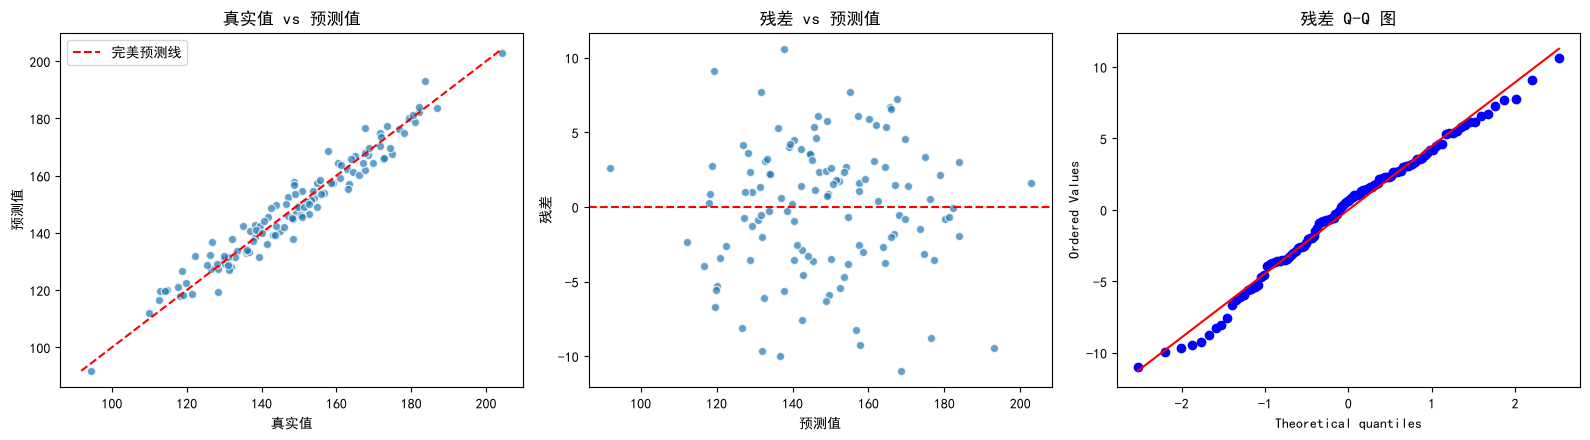

In [6]:
# ============================================================
# 6. 绘制真实值-预测值、残差图和 Q-Q 图
# ============================================================
fitted_values = model['fitted_values']
residuals = model['residuals']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 左图：真实值与预测值越接近，点越靠近红色虚线。
axes[0].scatter(y, fitted_values, alpha=0.7, edgecolors='white')
line_min = min(y.min(), fitted_values.min())
line_max = max(y.max(), fitted_values.max())
axes[0].plot([line_min, line_max], [line_min, line_max],
             color='red', linestyle='--', label='完美预测线')
axes[0].set_xlabel('真实值')
axes[0].set_ylabel('预测值')
axes[0].set_title('真实值 vs 预测值')
axes[0].legend()

# 中图：残差应围绕 0 随机散布，不应出现明显趋势。
axes[1].scatter(fitted_values, residuals, alpha=0.7, edgecolors='white')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('预测值')
axes[1].set_ylabel('残差')
axes[1].set_title('残差 vs 预测值')

# 右图：Q-Q 图点越接近直线，越支持残差近似正态。
stats.probplot(residuals, dist='norm', plot=axes[2])
axes[2].set_title('残差 Q-Q 图')

plt.tight_layout()
plt.show()

## 6. 使用建议与注意事项

1. **不要只看 $R^2$**：样本外预测能力、调整 $R^2$、残差诊断和业务解释同样重要。
2. **检查共线性**：VIF 较高时，单个系数可能不稳定，但模型整体预测可能仍可用。
3. **检查异常值和杠杆点**：极端样本可能显著改变回归系数，应结合业务判断是否剔除。
4. **分类变量要编码**：例如地区、行业等分类变量需先做独热编码。
5. **时间序列慎用普通 OLS**：若存在明显趋势、季节性或自相关，应采用相应的时间序列模型或稳健标准误。
6. **p 值不是因果证明**：显著性只说明在指定模型和假设下存在统计关联，不能自动推出因果关系。

In [ ]:
# ============================================================
# 复用校验：模块版与上面 Notebook 版在同一批数据上结果一致
# ============================================================
model_mod = 建模工具.fit_multiple_linear_regression(
    X, y, feature_names=feature_names, confidence=0.95
)
pred_mod = 建模工具.predict_multiple_linear_regression(model_mod, new_samples[feature_names])

print("系数一致：", bool(np.allclose(model_mod["coefficients"], model["coefficients"])))
print("预测一致：", bool(np.allclose(pred_mod, new_predictions)))